In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from scipy.integrate import ode, odeint, solve_ivp, solve_bvp
from scipy import optimize
from matplotlib.cm import ScalarMappable

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern']})
plt.rcParams.update({'font.size': 10})

def runge_kutta_4(f, t, y0, *args, **kwargs):
    """
    Metoda Runge-Kutta 4. reda za reševanje diferencialne enačbe: y' = f(t, y)
    
    :param f: funkcija, ki jo kličemo s parametroma t in y in vrne 
              vrednost prvega odvoda
    :param t: ekvidistanten časovni vektor oz. neodvisna spremenljivka
    :param y0: začetna vrednost
    :param args: dodatni argumenti funkcije f (brezimenski)
    :param kwargs: dodatni argumenti funkcije f (poimenovani)
    :return y: funkcijske vrednosti.
    """
    def RK4(f, t, y, *args, **kwargs):
        k0 = h*f(t, y, *args, **kwargs)
        k1 = h*f(t + h/2.0, y + k0/2.0, *args, **kwargs)
        k2 = h*f(t + h/2.0, y + k1/2.0, *args, **kwargs)
        k3 = h*f(t + h, y + k2, *args, **kwargs)
        return (k0 + 2.0*k1 + 2.0*k2 + k3)/6.0
    
    y = np.zeros(shape=(len(t),len(y0)))
    y[0] = y0
    h = t[1]-t[0]

    for i, ti in enumerate(t[1:]):
        y[i+1] = y[i] + RK4(f, ti, y[i], *args, **kwargs)
        
    return y.T

In [2]:
def de(t,y):
    x,y,vx,vy = y
    u = vx #dxdt
    v = vy #dydt
    dudt=-x-2*x*y
    dvdt=-y-x**2+y**2
    return np.array([u,v,dudt,dvdt])
def potential(x, y):
    return 0.5*(x**2+y**2) + x**2*y - y**3/3
def energija(t, y):
    x,y,vx,vy = y
    U = potential(x,y)
    T = 0.5*(vx**2+vy**2)
    return U+T #=H

# orbite

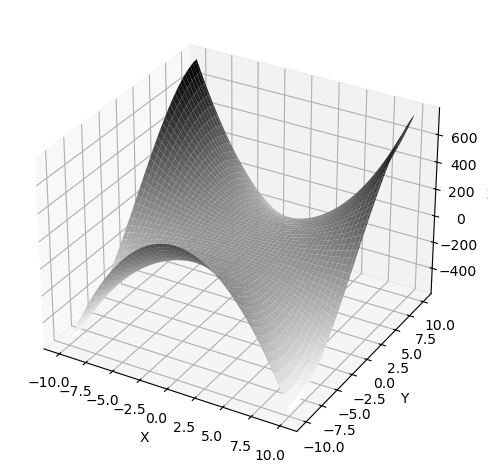

In [3]:
a=10
x = np.linspace(-a, a, 100)
y = np.linspace(-a, a, 100)
X, Y = np.meshgrid(x, y)
Z = potential(X, Y)
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='binary')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.tight_layout()
#plt.savefig('slike/potencial.pdf')

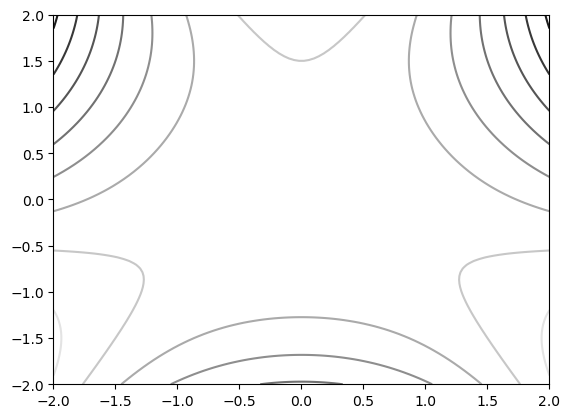

In [4]:
# H-H potencial
x = np.linspace(-2, 2, 100)
y = np.linspace(-2, 2, 100)
X, Y = np.meshgrid(x, y)
Z = potential(X, Y)
plt.contour(X, Y, Z, cmap='binary')

0.09 0.16666666666666666


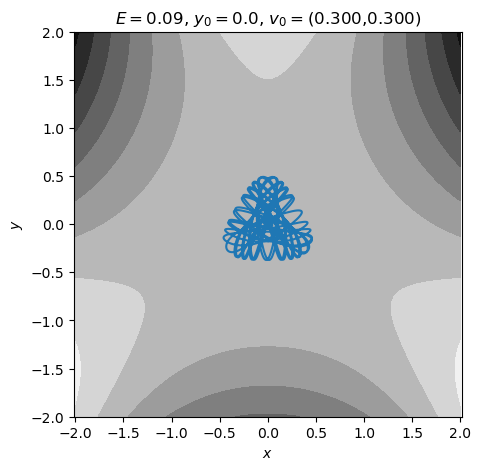

In [5]:
#ROČNI PARAMETRI
x0, y0 = 0., 0.0 #ZP lega (y0 je med [0,0] in [0,1]), sym:x0=0

en = 1/6
vi = 2**0.5 * (en-potential(x=0,y=y0))**0.5 #hitrost komponenta
v0 = (0, vi)
vi=0.3
v0 = (vi,vi)

dt = 0.001
t_max = 150
t=np.arange(0., t_max, dt)
y_zp=np.array([x0,y0,v0[0],v0[1]])
e = 0.5*(v0[0]**2+v0[1]**2) + potential(x0,y0)
print(e, 1/6)

method='RK45'
#res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method=method,t_eval=t)
res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method=method, max_step=100*dt) #auto dt
y = res.y
t = res.t
E = energija(t,y)

plt.figure(figsize=(5,5))
plt.contourf(X, Y, Z, cmap='binary')
plt.plot(x0,y0, 'o')
plt.plot(y[0], y[1],'C0-')
plt.title(f'$E=${e:.2f}, $y_0=${y0}, $v_{{0}}=$({v0[0]:.3f},{v0[1]:.3f})')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.gca().set_aspect('equal', adjustable='box')
plt.xlim((-2,2))
plt.ylim((-2,2))
plt.axis('equal');
#plt.savefig(f'slike/primer3.pdf')

In [6]:
x0, y0 = 0., 0.5 #ZP lega (y0 je med [0,0] in [0,1]), sym:x0=0

en = 1/6
vi = 2**0.5 * (en-potential(x=0,y=y0))**0.5 #hitrost komponenta
v0 = (vi, 0)

dt = 0.0001
t_max = 100
y_zp=np.array([x0,y0,v0[0],v0[1]])

method='RK45'
res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method=method, max_step=100*dt) #auto dt
y = res.y
t1 = res.t
E1 = energija(t1,y)

#########
x0, y0 = 0., 0.0 #ZP lega (y0 je med [0,0] in [0,1]), sym:x0=0

en = 1/6
vi = 2**0.5 * (en-potential(x=0,y=y0))**0.5 #hitrost komponenta
v0 = (0, vi)
y_zp=np.array([x0,y0,v0[0],v0[1]])

method='RK45'
res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method=method, max_step=100*dt) #auto dt
y = res.y
t2 = res.t
E2 = energija(t2,y)

###############
x0, y0 = 0., 0.0 #ZP lega (y0 je med [0,0] in [0,1]), sym:x0=0
v0 = (0.25,0.25)
y_zp=np.array([x0,y0,v0[0],v0[1]])

method='RK45'
res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method=method, max_step=100*dt) #auto dt
y = res.y
t3 = res.t
E3 = energija(t3,y)

Text(0, 0.5, '$E$')

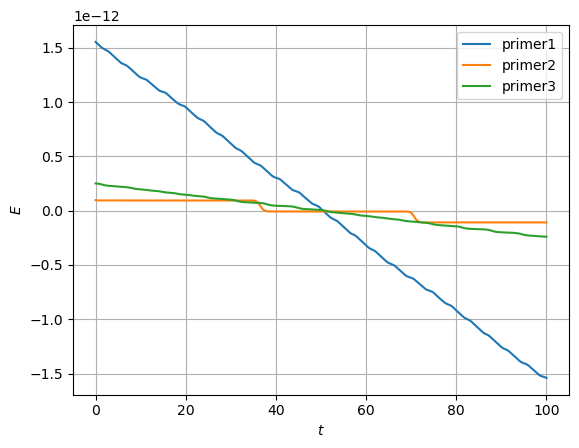

In [7]:
E_avg=np.average(E1)
plt.plot(t1,E1-E_avg, label='primer1')

E_avg=np.average(E2)
plt.plot(t2[:-1],E2[:-1]-E_avg, label='primer2')

E_avg=np.average(E3)
plt.plot(t3,E3-E_avg, label='primer3')

plt.grid()
plt.legend()
plt.xlabel('$t$')
plt.ylabel('$E$')
#plt.savefig('slike/energija_primeri.pdf')

[0.5 0.4 0.3 0.2 0.1]
[0.1767766952966369, 0.11313708498984763, 0.0636396103067893, 0.02828427124746191, 0.007071067811865477]


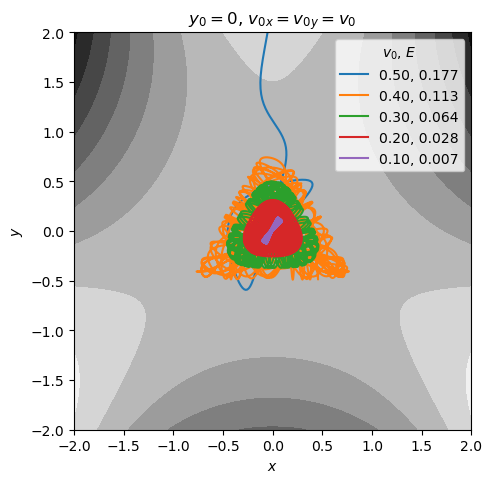

In [8]:
# konst. E
x0 = 0 #zaradi sym
y0 = 0. #ZP lega [0,1]
v_x0 = 0
v_y0 = 0

dt = 0.01
t_max = 300#0
t=np.arange(0., t_max, dt)

en = 0.001
N=5
# hitrosti = [] #2**0.5 * (en-potential(x0,y_zač))**0.5
# for i in range(N):
#     v_i = 2**0.5 * (en-potential(x0,y0))**0.5
#     if en-potential(x0,y0[i]) < 0:
#         v_i = 2**0.5 * (-en+potential(x0,y0[i]))**0.5
#     hitrosti.append(v_i)
vi = np.linspace(0.1, 0.5, N)
vi = vi[::-1]
print(vi)
en = []
for i in range(N):
    e = 0.5*vi[i]**2*2**0.5 + potential(x0,y0)
    en.append(e)
print(en)
resitve = []
for i in range(N):
    v_x0 = vi[i]
    v_y0 = vi[i]
    y_zp=np.array([x0,y0,v_x0,v_y0])
    #e = 0.5*(v_x0**2) + potential(x0,y0)

    method='RK45'
    #res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method=method,t_eval=t)
    res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method=method, max_step=10*dt) #auto dt
    y = res.y
    t = res.t
    resitve.append((t,y))
    #E = energija(t,y)

plt.figure(figsize=(5,5))
plt.contourf(X, Y, Z, cmap='binary')
for i in range(N):
    #plt.plot(resitve[i][1][0][0], resitve[i][1][1][0],'o', label=f'{y_zač[i]:.2f}')
    plt.plot(resitve[i][1][0], resitve[i][1][1], label=f'{vi[i]:.2f}, {en[i]:.3f}')
plt.legend(title='$v_0$, $E$')
plt.title('$y_0=0$, $v_{0x}=v_{0y}=v_0$')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.axis('equal')
plt.gca().set_aspect('equal', adjustable='box')
plt.xlim((-2,2))
plt.ylim((-2,2))
plt.tight_layout()
#plt.savefig('slike/razlicne_v0.pdf')

# Poincare

In [9]:
def nicle(y):
    i_presek = []
    for i in range(len(y)-1):
        if (y[i] > 0)&(y[i+1] <= 0):
            i_presek.append(i)
        if (y[i] < 0)&(y[i+1] >= 0):
            i_presek.append(i)
    return np.array(i_presek)
def preseki(data,t):
    x,y,vx,vy=np.array(data)
    i_presek = nicle(x) #preseki z x-osjo
    #print('indeksi:',i_presek)
    y_preseki = []
    vy_preseki= []
    time = []
    for i in i_presek: #interpolacija
        # t0 = i / len(y)
        # t1 = (i + 1) / len(y)
        t0, t1  = t[i], t[i+1]
        t_interp = np.linspace(t0, t1, 100)
        x0, x1 = x[i], x[i+1]
        y0, y1 = y[i], y[i+1]
        vy0, vy1 = vy[i], vy[i+1]
        #print('y vrednosti: ',y[i],y[i+1])
        presek_index = nicle(np.interp(t_interp, [t0, t1], [x0, x1])) #lin inperpolacija do x=0
        y_presek = np.interp(t_interp, [t0, t1], [y0, y1])[presek_index]
        vy_presek = np.interp(t_interp, [t0, t1], [vy0, vy1])[presek_index]
        t_presek = t_interp[presek_index]
        #print('presečišče: ',y_presek,  vy_presek)
        y_preseki.extend(y_presek)
        vy_preseki.extend(vy_presek)
        time.append(t_presek)
    return y_preseki, vy_preseki, time

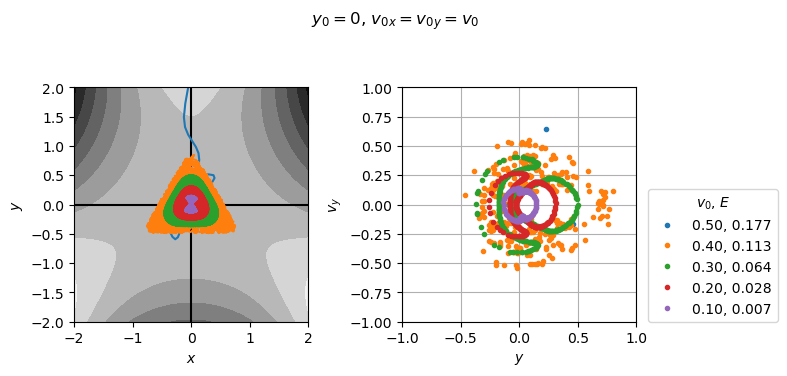

In [10]:
# ročno
x0 = 0 #zaradi sym
y0 = 0.0 #ZP lega [0,1]
v_x0 = 0
v_y0 = 0
dt = 0.3 #max dovoljen korak; preveliki koraki -> li. interp ni OK!
t_max = 1000

################
# en = 0.1
# vi = 2**0.5 * (en-potential(x0,y0))**0.5
# v_x0 = vi

###########################
# vi = 0.3 #v_x0 = v_y0 = vi
# v_x0 = vi
# v_y0 = vi
# e = 0.5*vi**2*2**0.5 + potential(x0,y0)
# print(f'E = {e:.5f}, mejna: {1/6:.5f}')

# y_zp=np.array([x0,y0,v_x0,v_y0])
# res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method='RK45', max_step=dt)
# y = res.y 
# t = res.t
# y_preseki, vy_preseki, t_preseki = preseki(y,t)

#####################
N=5
vi = np.linspace(0.1, 0.5, N)
vi = vi[::-1]
en = []
for i in range(N):
    e = 0.5*vi[i]**2*2**0.5 + potential(x0,y0)
    en.append(e)
resitve = []
poincare = []
for i in range(N):
    v_x0 = vi[i]
    v_y0 = vi[i]
    y_zp=np.array([x0,y0,v_x0,v_y0])
    res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method='RK45', max_step=dt) #auto dt
    y = res.y
    t = res.t
    y_preseki, vy_preseki, t_preseki = preseki(y,t)
    resitve.append((y[0],y[1])) #lege
    poincare.append((y_preseki, vy_preseki))

fig, (ax1,ax2) = plt.subplots(1,2, figsize=(8,4))
ax1.contourf(X, Y, Z, cmap='binary')
ax1.axvline(0,color='k')
ax1.axhline(0,color='k')
ax1.axis('equal')
ax1.set_aspect('equal', adjustable='box')
ax1.set_xlim((-2,2))
ax1.set_ylim((-2,2))
ax1.set_xlabel('$x$')
ax1.set_ylabel('$y$')

ax2.set_xlabel('$y$')
ax2.set_ylabel('$v_y$')
ax2.axis('equal')
ax2.set_aspect('equal', adjustable='box')
ax2.set_xlim((-1,1))
ax2.set_ylim((-1,1))
ax2.grid()

# ax1.plot(y[0,0], y[1,0],'oC0')
# ax1.plot(y[0],y[1])
# ax2.plot(y_preseki, vy_preseki,'.')
for i in range(N):
    ax1.plot(resitve[i][0], resitve[i][1],'-')
    ax2.plot(poincare[i][0], poincare[i][1],'.', label=f'{vi[i]:.2f}, {en[i]:.3f}')
plt.legend(loc=(1.05,0),title='$v_0$, $E$')
plt.suptitle('$y_0=0$, $v_{0x}=v_{0y}=v_0$')
plt.tight_layout()
#plt.savefig('slike/poincare_razlicne_v0.pdf')

### le v_0y


	E = 0.01
1701 -> neg koren!!!!
298/298, E=0.01000
	E = 0.05
1272 -> neg koren!!!!
727/727, E=0.05000
	E = 0.1
865 -> neg koren!!!!
1134/1134, E=0.10000
	E = 0.15
391 -> neg koren!!!!
1608/1608, E=0.15000
	E = 0.16
240 -> neg koren!!!!
1759/1759, E=0.16000
	E = 0.16666666666666666
0 -> neg koren!!!!
1999/1999, E=0.16667
	E = 0.17

2000/2000, E=0.17000
	E = 0.2



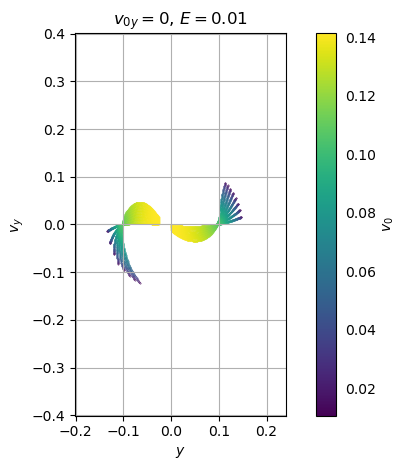

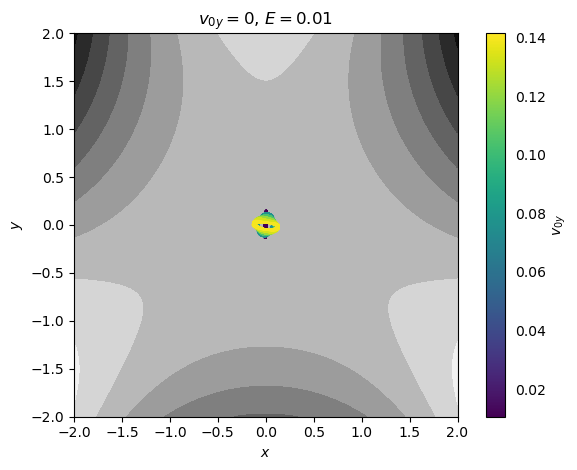

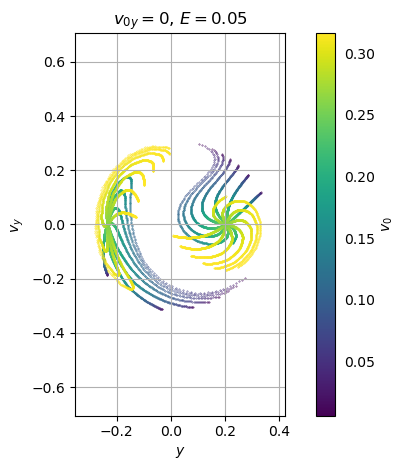

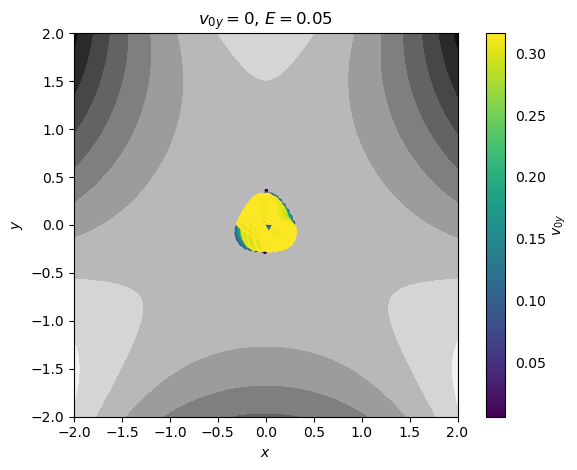

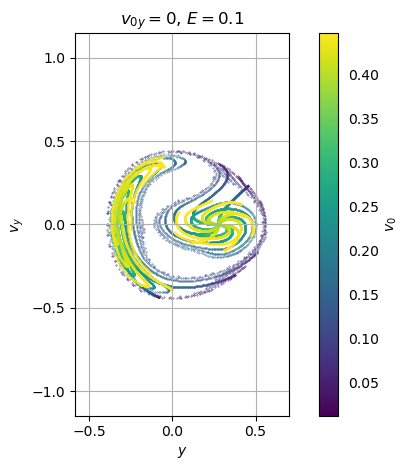

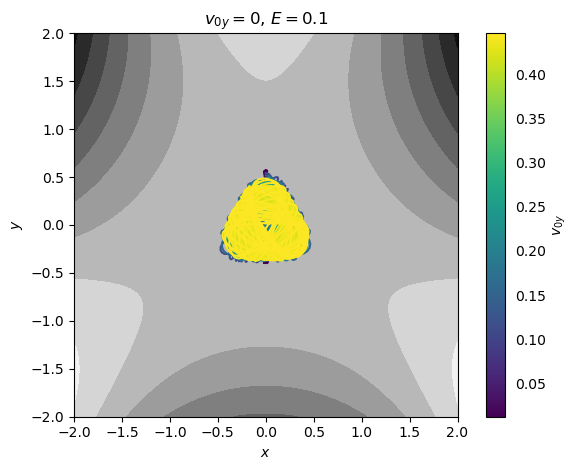

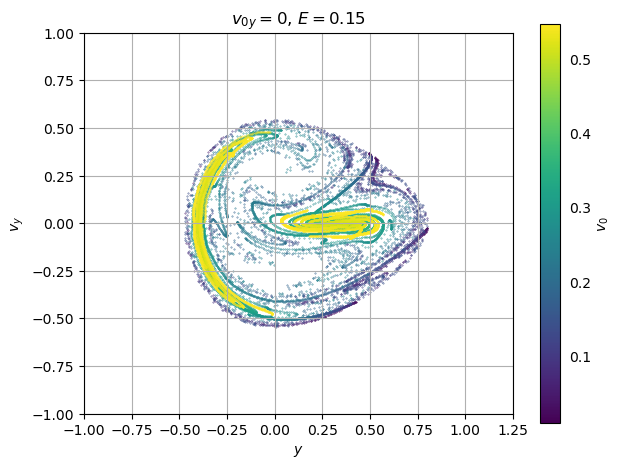

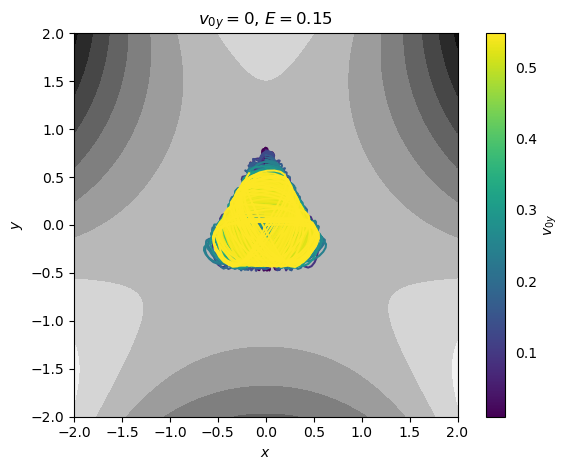

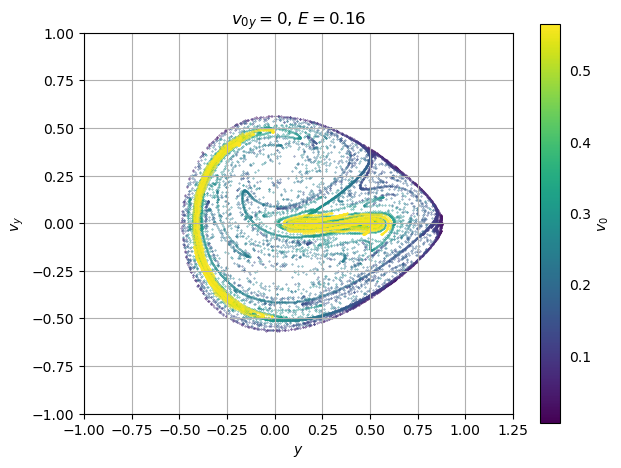

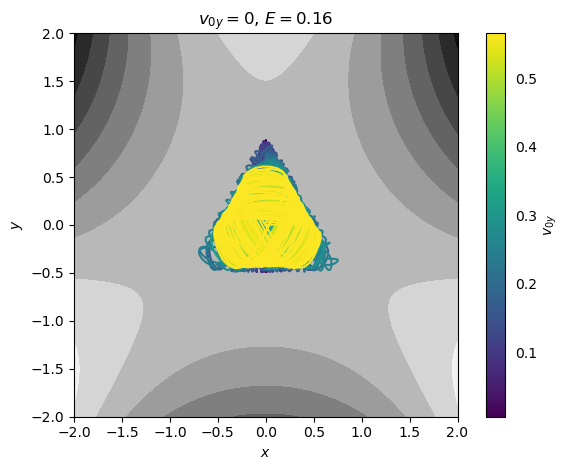

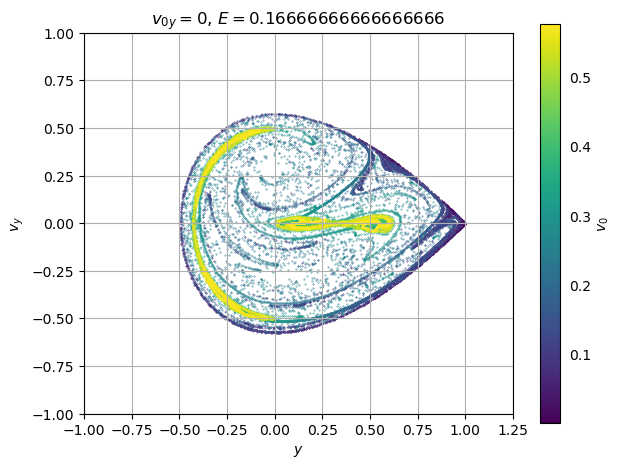

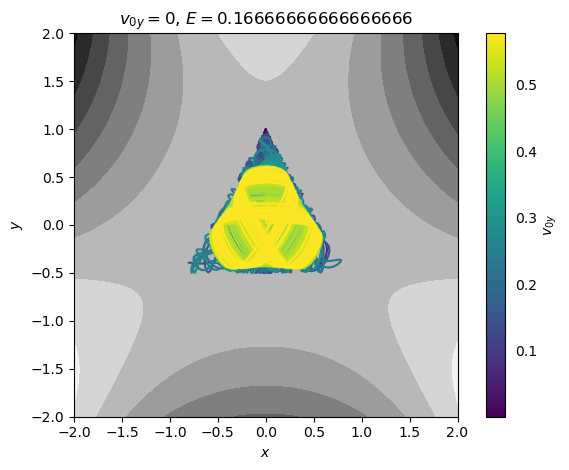

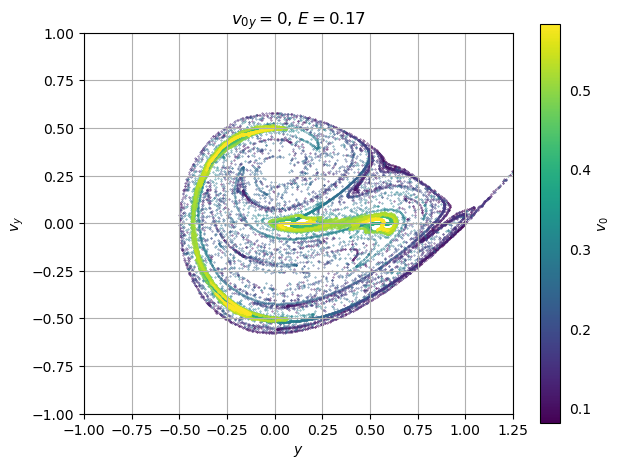

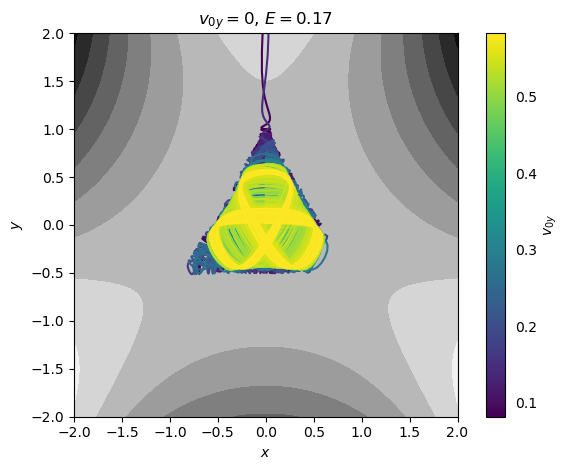

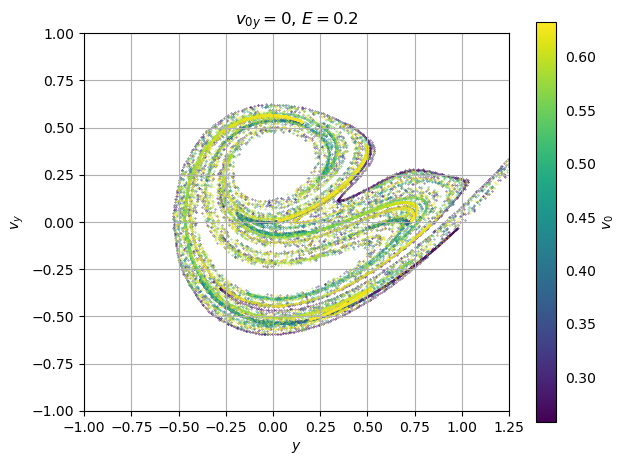

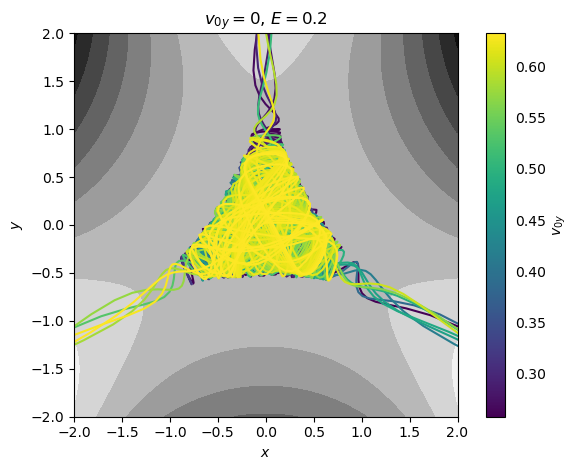

In [320]:
# v_y0 = 0 KONST E!!!
x0 = 0 #zaradi sym
y0 = 0. #ZP lega [0,1]
v_x0 = 0
v_y0 = 0
dt = 0.25 #max dovoljen korak; preveliki koraki -> li. interp ni OK!
t_max = 500
naslov = '$v_{0y}=0$'

energije = [0.01, 0.05, 0.1, 0.15, 0.16, 1/6, 0.17, 0.2] #min 0,01 -> večanje t_max!!!
for en in energije:
    print('\n\tE =',en)

    N = 2000 # št vzorcev
    if en <= 0.1:
        t_max = 50
    else: t_max = 50
    
    y_zač = np.linspace(1,0,N) #y0
    y_0_list = []
    v_0_list =[] #=v_0x
    for i in range(N):
        a = en-potential(x0,y_zač[i])
        if a>0:
            v_0_list.append((2*a)**0.5)
            y_0_list.append(y_zač[i])
        else: print(f'{i} -> neg koren!!!!', end='\r')
        #print('E:',energija(0, [x0,y_zač[i],vi,v_y0]))
    N=len(y_0_list)
    y_0_list = np.array(y_0_list)

    poincare = []
    resitve = []
    i=0
    print()
    for i in range(N):
        y0 = y_0_list[i]
        v_x0 = v_0_list[i]
        e = potential(x0,y0) + 0.5*(v_x0**2+v_y0**2)
        print(f'{i+1}/{N}, E={e:.5f}',end='\r')
        if e-en > 1e-15: print('napaka')
        y_zp=np.array([x0,y0,v_x0,v_y0])
        res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method='RK45', max_step=dt)
        y = res.y 
        t = res.t
        y_preseki, vy_preseki, t_preseki = preseki(y,t)
        poincare.append([y_preseki,vy_preseki])
        resitve.append([y[0],y[1]])

    fig, ax = plt.subplots()
    v_min = min(v_0_list)
    v_max = max(v_0_list)
    normalized_v_0_list = [(v - v_min) / (v_max - v_min) for v in v_0_list]
    colors = plt.cm.viridis(normalized_v_0_list)
    for i in range(N):
        ax.scatter(poincare[i][0], poincare[i][1], c=[colors[i]], s=0.1) #najprej nestabilne!
    plt.axis('equal')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title(naslov+f', $E=${en}')
    plt.xlabel('$y$')
    plt.ylabel('$v_y$')
    a = -min(poincare[:][0][0])*1.5 #x
    b = -min(poincare[:][1][0])*1.5 #y
    if en>=0.15:
        plt.xlim((-1,1.25))
        plt.ylim((-1,1))
    # elif en > 0.1:
    #     plt.xlim((-a,a*2))
    #     plt.ylim((-b,b))
    else:
        plt.xlim((-a,a*1.2))
        plt.ylim((-b*2,b*2))
    plt.grid()
    sm = ScalarMappable(cmap=plt.cm.viridis)
    sm.set_array(v_0_list)
    cbar = fig.colorbar(sm, ax=ax, label='$v_{0}$')
    cbar.ax.yaxis.set_ticks_position('none')
    plt.tight_layout()
    plt.savefig(f'slike/poincare_v0x_E{en}.pdf')
    #plt.show()

    step = 10*5
    fig, ax = plt.subplots()
    for i in range(0,N,step):
        ax.plot(resitve[i][0], resitve[i][1],'-', color=colors[i])
    plt.contourf(X, Y, Z, cmap='binary')
    plt.title(naslov+f', $E=${en}')
    plt.xlabel('$x$')
    plt.ylabel('$y$')
    plt.axis('equal')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.xlim((-2,2))
    plt.ylim((-2,2))
    cbar = fig.colorbar(sm, ax=ax, label='$v_{0y}$')
    cbar.ax.yaxis.set_ticks_position('none')
    plt.tight_layout()
    plt.savefig(f'slike/poincare_tajektorije_v0y_E{en}.pdf')
    #plt.show()

### v_0x = v_0y


	E = 0.01
850 -> neg koren!!!!
149/149, E=0.01000
	E = 0.05
636 -> neg koren!!!!
363/363, E=0.05000
	E = 0.1
432 -> neg koren!!!!
567/567, E=0.10000
	E = 0.15
195 -> neg koren!!!!
804/804, E=0.15000
	E = 0.16
120 -> neg koren!!!!
879/879, E=0.16000
	E = 0.16666666666666666
0 -> neg koren!!!!
999/999, E=0.16667
	E = 0.17

1000/1000, E=0.17000
	E = 0.2



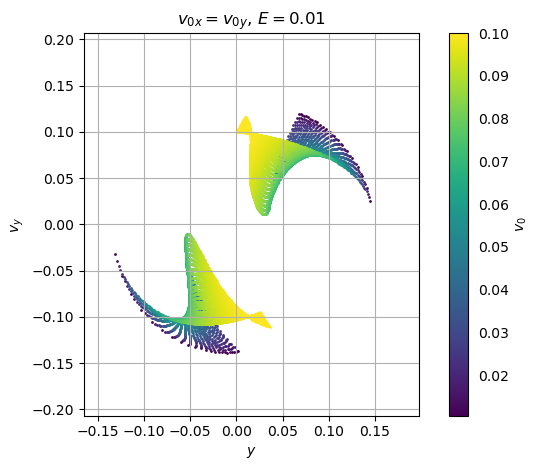

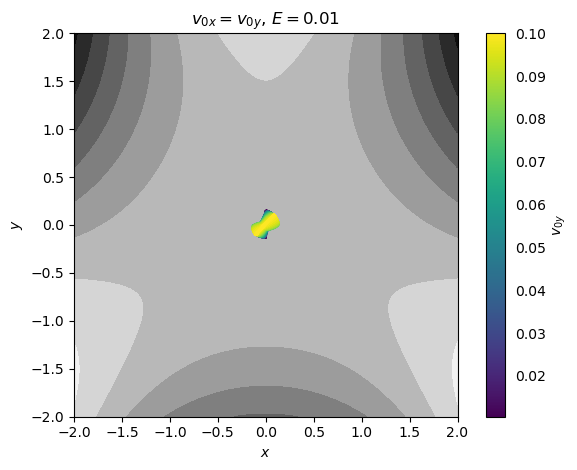

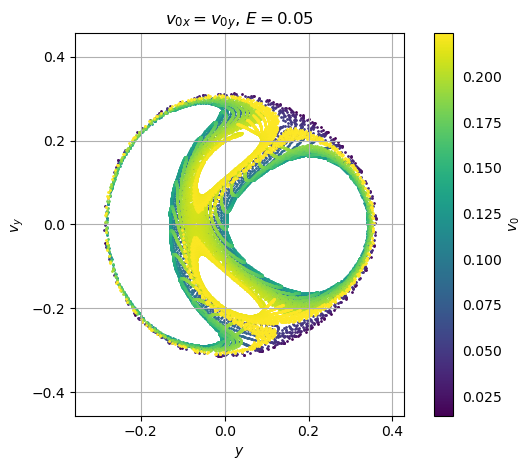

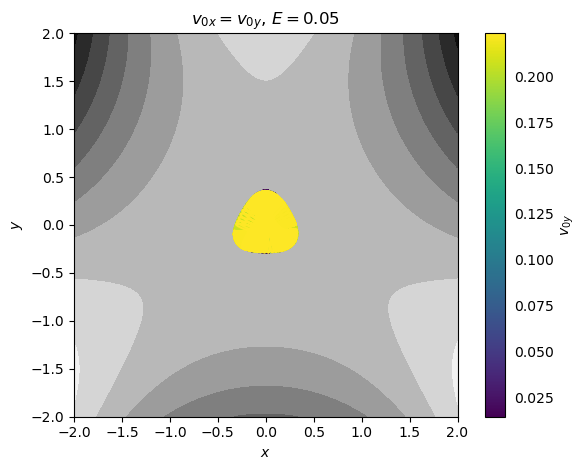

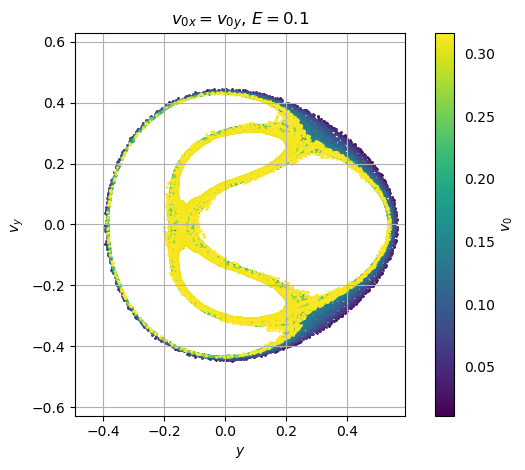

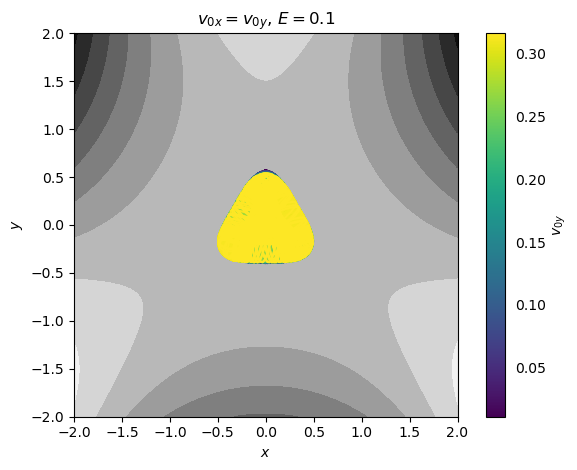

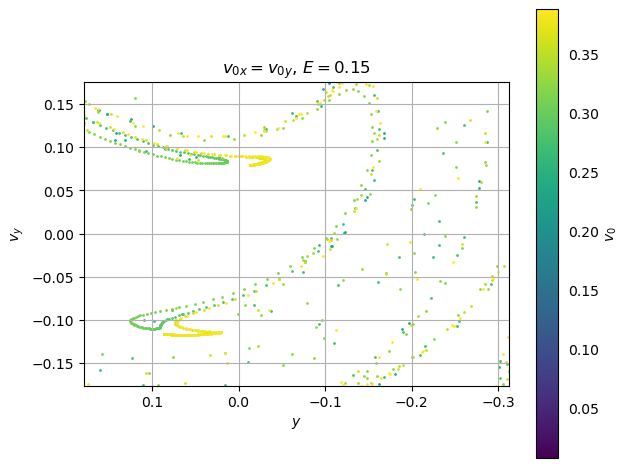

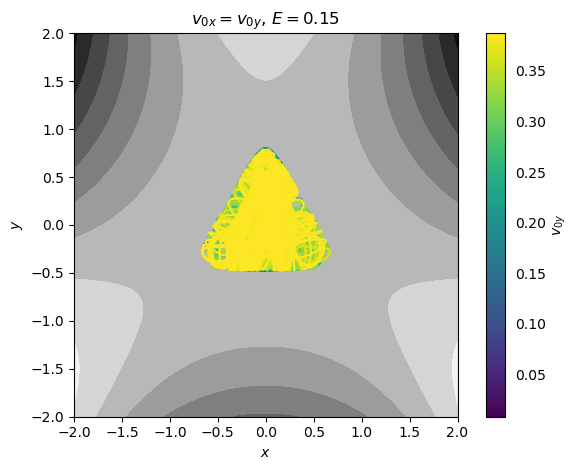

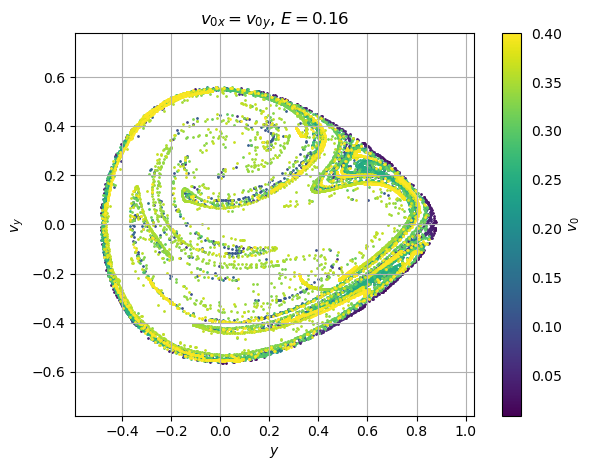

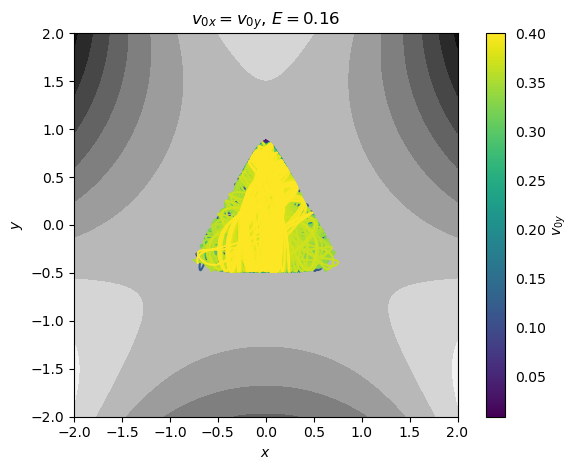

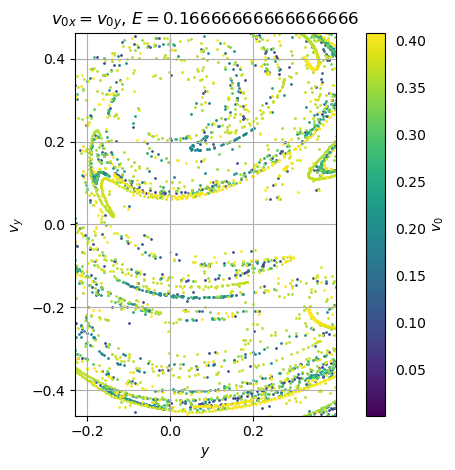

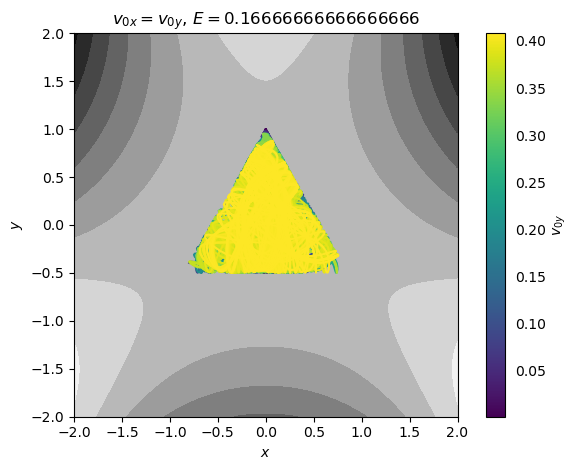

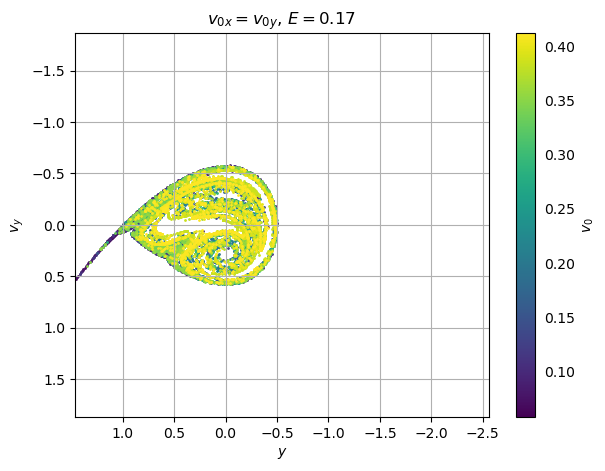

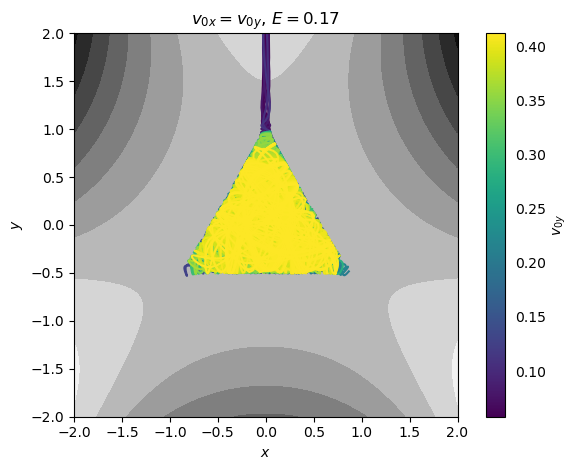

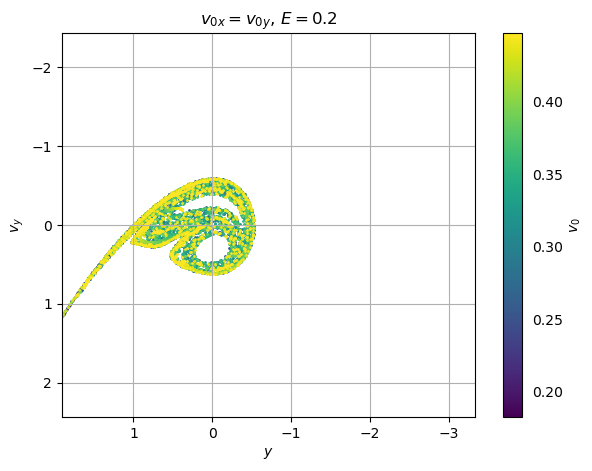

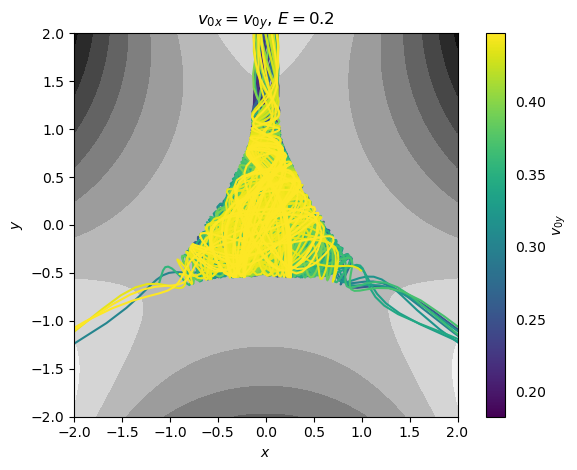

In [11]:
x0 = 0 #zaradi sym
y0 = 0. #ZP lega [0,1]
v_x0 = 0
v_y0 = 0
dt = 0.25 #max dovoljen korak; preveliki koraki -> li. interp ni OK!
naslov = '$v_{0x}=v_{0y}$'

energije = [0.01, 0.05, 0.1, 0.15, 0.16, 1/6, 0.17, 0.2] #min 0,01 -> večanje t_max!!!
for en in energije:
    print('\n\tE =',en)

    N = 1000 # št vzorcev
    if en <= 0.1:
        t_max = 150
    else: t_max = 50

    y_zač = np.linspace(1,0,N) #y0
    y_0_list = []
    v_0_list =[] #=v_0x=v_y0
    for i in range(N):
        a = en-potential(x0,y_zač[i])
        if a>0:
            v_0_list.append(a**0.5)
            y_0_list.append(y_zač[i])
        else: print(f'{i} -> neg koren!!!!', end='\r')
        #print('E:',energija(0, [x0,y_zač[i],vi,v_y0]))
    N=len(y_0_list)
    v_0_list = np.array(v_0_list)

    poincare = []
    resitve = []
    print()
    for i in range(N):
        y0 = y_0_list[i]
        v_x0 = v_0_list[i]
        v_y0 = v_0_list[i]
        e = potential(x0,y0) + 0.5*(v_x0**2+v_y0**2)
        print(f'{i+1}/{N}, E={e:.5f}',end='\r')
        if e-en > 1e-15: print('napaka')
        y_zp=np.array([x0,y0,v_x0,v_y0])
        res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method='RK45', max_step=dt)
        y = res.y
        t = res.t
        y_preseki, vy_preseki, t_preseki = preseki(y,t)
        poincare.append([y_preseki,vy_preseki])
        resitve.append([y[0],y[1]])
  

    fig, ax = plt.subplots()
    v_min = min(v_0_list)
    v_max = max(v_0_list)
    normalized_v_0_list = [(v - v_min) / (v_max - v_min) for v in v_0_list]
    colors = plt.cm.viridis(normalized_v_0_list)
    for i in range(N):
        ax.scatter(poincare[i][0], poincare[i][1], c=[colors[i]], s=1) #najprej nestabilne!
    plt.axis('equal')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title(naslov+f', $E=${en}')
    plt.xlabel('$y$')
    plt.ylabel('$v_y$')
    a = -min(poincare[:][0][0])*1.25 #x
    b = -min(poincare[:][1][0])*1.6 #y
    if en >= 0.15: plt.xlim((-a,a*1.75))
    elif en >1/6: plt.xlim()
    else: plt.xlim((-a,a*1.2))
    plt.ylim((-b,b))
    plt.grid()
    sm = ScalarMappable(cmap=plt.cm.viridis)
    sm.set_array(v_0_list)
    cbar = fig.colorbar(sm, ax=ax, label='$v_{0}$')
    cbar.ax.yaxis.set_ticks_position('none')
    plt.tight_layout()
    #plt.savefig(f'slike/poincare_v0x_v0y_E{en}.pdf')
    #plt.show()

    step = 10*1
    fig, ax = plt.subplots()
    for i in range(0,N,step):
        ax.plot(resitve[i][0], resitve[i][1],'-', color=colors[i])
    plt.contourf(X, Y, Z, cmap='binary')
    plt.title(naslov+f', $E=${en}')
    plt.xlabel('$x$')
    plt.ylabel('$y$')
    plt.axis('equal')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.xlim((-2,2))
    plt.ylim((-2,2))
    cbar = fig.colorbar(sm, ax=ax, label='$v_{0y}$')
    cbar.ax.yaxis.set_ticks_position('none')
    plt.tight_layout()
    #plt.savefig(f'slike/poincare_tajektorije_v0x_v0y_E{en}.pdf')
    #plt.show()

### splošno

In [294]:
# poljuben v_y0
x0 = 0 #zaradi sym
y0 = 0. #ZP lega [0,1]
v_x0 = 0
v_y0 = 0
dt = 0.2 #max dovoljen korak; preveliki koraki -> li. interp ni OK!
t_max = 500
N = 100
en = 0.1
print('E =',en)

naslov = 'poljuben $v_0$'
y_zač = np.linspace(0.5,0,N) #y0
v_y0_data = np.linspace(0,1,N)
v_x0_list = [] #=v_0x
v_y0_list = [] #=v_y0
y_0_list = [] #y_0
v_0_list=[]
for i in range(N):
    a = en-potential(x0,y_zač[i])
    pod_koren = 2*a - v_y0_data[i]**2
    if pod_koren>0:
        v_x0_list.append(pod_koren**0.5)
        v_y0_list.append(v_y0_data[i])
        y_0_list.append(y_zač[i])
        v_0_list.append((v_x0_list[i]**2+v_y0_list[i]**2)**0.5)
    else: print(f'{i} -> neg koren!!!!', end='\r')
N=len(y_0_list)
print(N)
v_0_list = np.array(v_0_list)

poincare = []
resitve = []
for i in range(N):
    y0 = y_0_list[i]
    v_x0 = v_x0_list[i]
    v_y0 = v_y0_list[i]
    e = potential(x0,y0) + 0.5*(v_x0**2+v_y0**2)
    print(f'{i+1}/{N}, E={e:.5f}',end='\r')
    if e-en > 1e-15: print('napaka')
    y_zp=np.array([x0,y0,v_x0,v_y0])
    res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method='RK45', max_step=dt)
    y = res.y
    t = res.t
    y_preseki, vy_preseki, t_preseki = preseki(y,t)
    poincare.append([y_preseki,vy_preseki])
    resitve.append([y[0],y[1]])

E = 0.1
34 -> neg koren!!!!


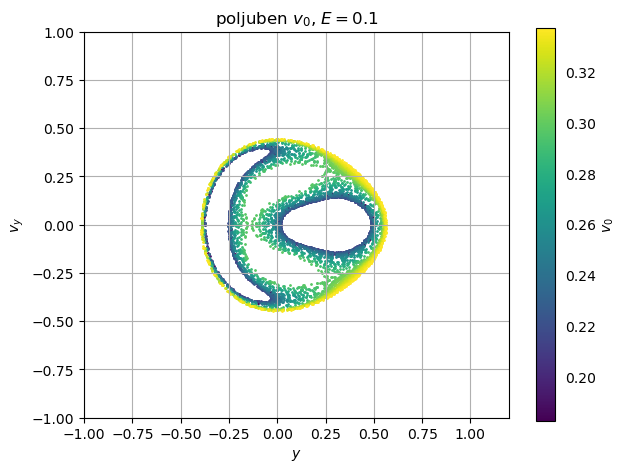

In [295]:
fig, ax = plt.subplots()
v_min = min(v_0_list)
v_max = max(v_0_list)
normalized_v_0_list = [(v - v_min) / (v_max - v_min) for v in v_0_list]
colors = plt.cm.viridis(normalized_v_0_list)
for i in range(N):
    ax.scatter(poincare[i][0], poincare[i][1], c=[colors[i]], s=1) #najprej nestabilne!
plt.axis('equal')
plt.gca().set_aspect('equal', adjustable='box')
plt.title(naslov+f', $E=${en}')
plt.xlabel('$y$')
plt.ylabel('$v_y$')
a=1
plt.xlim((-a,a+0.2))
plt.ylim((-a,a))
plt.grid()
sm = ScalarMappable(cmap=plt.cm.viridis)
sm.set_array(v_0_list)
cbar = fig.colorbar(sm, ax=ax, label='$v_{0}$')
cbar.ax.yaxis.set_ticks_position('none')
plt.tight_layout()
#plt.savefig(f'slike/poincare_v_0y_v0x_E{en}.pdf')
plt.show()


	E = 0.1
339 -> neg koren!!!!
339/339, E=0.10000
	E = 0.15
497 -> neg koren!!!!
497/497, E=0.15000
	E = 0.16
521 -> neg koren!!!!
521/521, E=0.16000
	E = 0.16666666666666666
537 -> neg koren!!!!
537/537, E=0.16667
	E = 0.17
544 -> neg koren!!!!
544/544, E=0.17000
	E = 0.2
605 -> neg koren!!!!


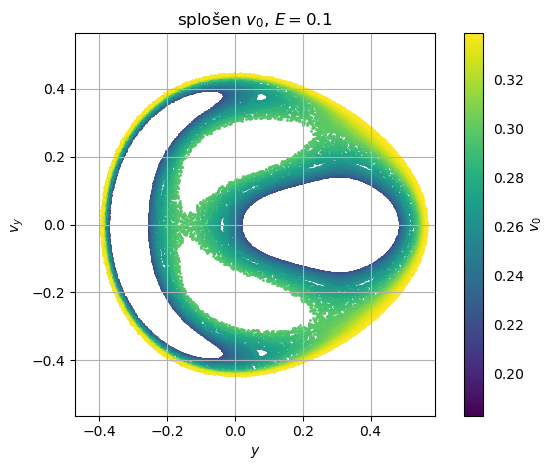

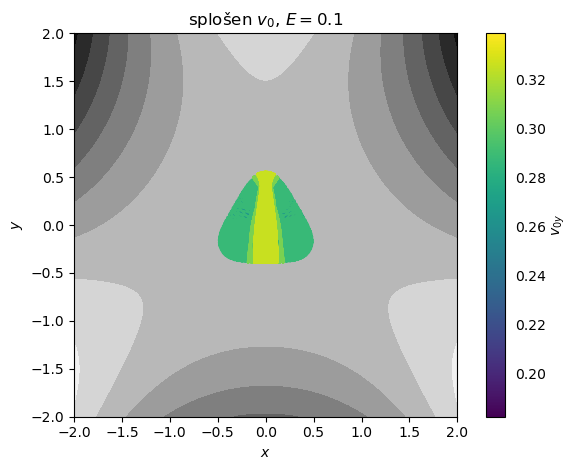

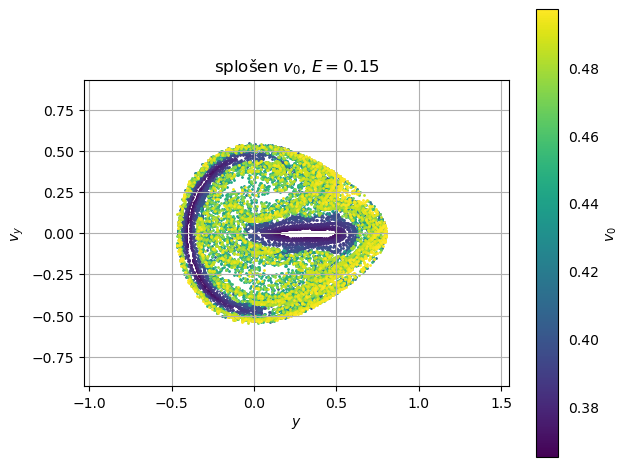

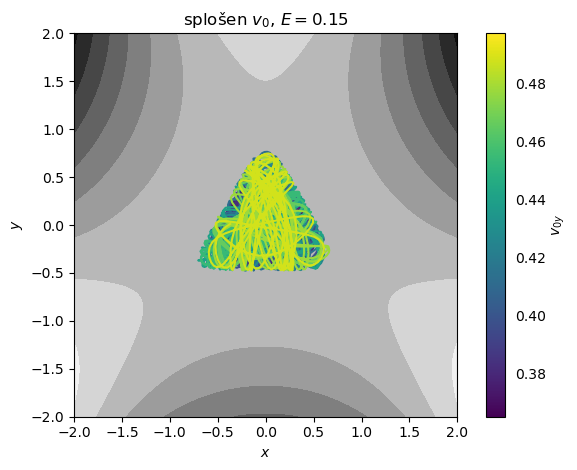

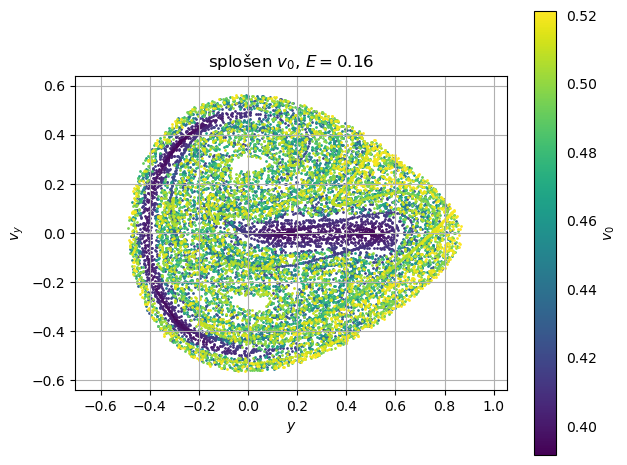

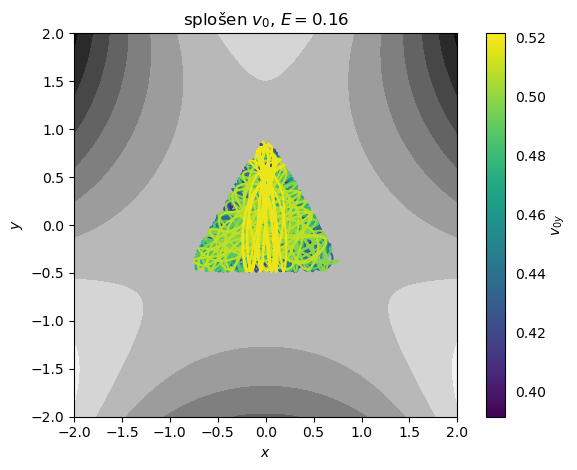

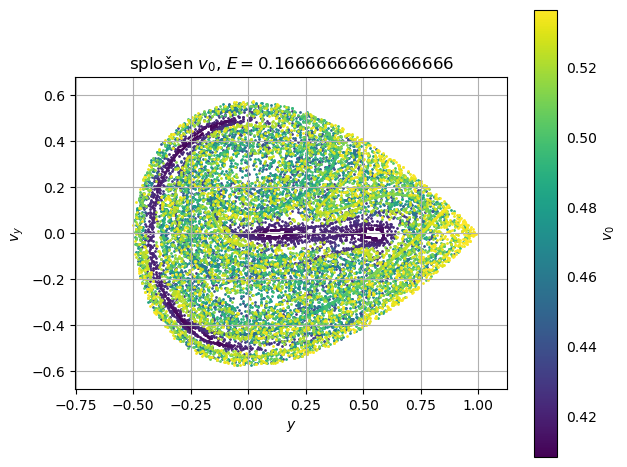

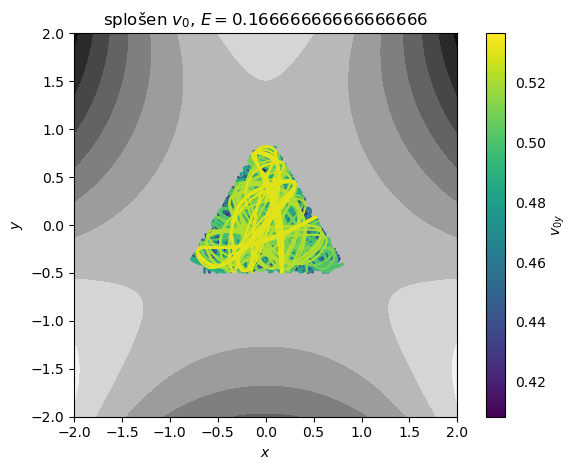

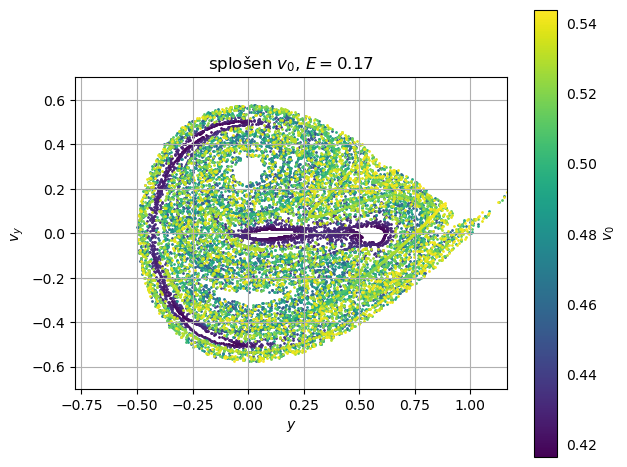

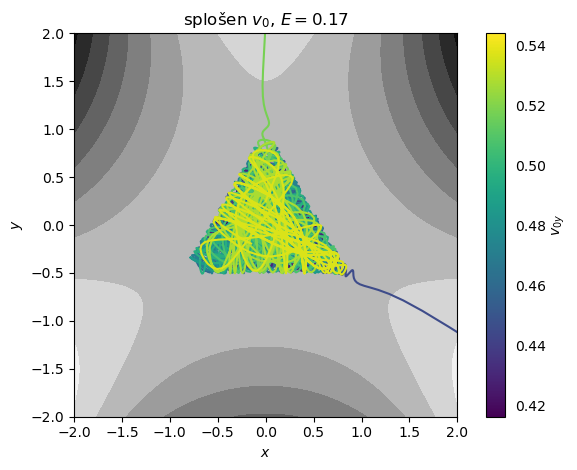

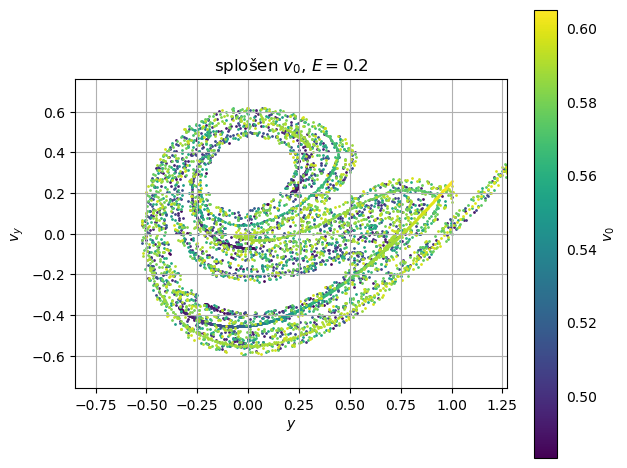

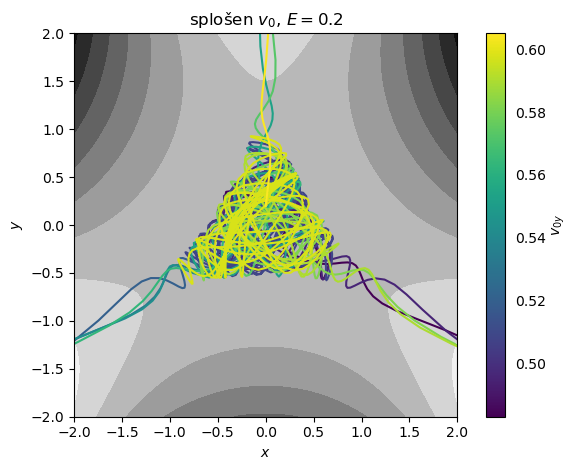

In [302]:
x0 = 0 #zaradi sym
y0 = 0. #ZP lega [0,1]
v_x0 = 0
v_y0 = 0
dt = 0.25 #max dovoljen korak; preveliki koraki -> li. interp ni OK!
naslov = 'splošen $v_0$'

energije = [0.1, 0.15, 0.16, 1/6, 0.17, 0.2] #min 0,1 TUKAJ MANJ!!
for en in energije:
    print('\n\tE =',en)

    N = 1000 # št vzorcev
    if en <= 0.1:
        t_max = 500
    else: t_max = 100

    y_zač = np.linspace(0.5,0,N) #y0
    v_y0_data = np.linspace(0,1,N)
    v_x0_list = [] #=v_0x
    v_y0_list = [] #=v_y0
    y_0_list = [] #y_0
    v_0_list=[]
    for i in range(N):
        a = en-potential(x0,y_zač[i])
        pod_koren = 2*a - v_y0_data[i]**2
        if pod_koren>0:
            v_x0_list.append(pod_koren**0.5)
            v_y0_list.append(v_y0_data[i])
            y_0_list.append(y_zač[i])
            v_0_list.append((v_x0_list[i]**2+v_y0_list[i]**2)**0.5)
        else: print(f'{i} -> neg koren!!!!', end='\r')
    N=len(y_0_list)
    print(N)
    v_0_list = np.array(v_0_list)

    poincare = []
    resitve = []
    for i in range(N):
        y0 = y_0_list[i]
        v_x0 = v_x0_list[i]
        v_y0 = v_y0_list[i]
        e = potential(x0,y0) + 0.5*(v_x0**2+v_y0**2)
        print(f'{i+1}/{N}, E={e:.5f}',end='\r')
        if e-en > 1e-15: print('napaka')
        y_zp=np.array([x0,y0,v_x0,v_y0])
        res = solve_ivp(de,y0=y_zp, t_span=(0.,t_max), method='RK45', max_step=dt)
        y = res.y
        t = res.t
        y_preseki, vy_preseki, t_preseki = preseki(y,t)
        poincare.append([y_preseki,vy_preseki])
        resitve.append([y[0],y[1]])
  

    fig, ax = plt.subplots()
    v_min = min(v_0_list)
    v_max = max(v_0_list)
    normalized_v_0_list = [(v - v_min) / (v_max - v_min) for v in v_0_list]
    colors = plt.cm.viridis(normalized_v_0_list)
    for i in range(N):
        ax.scatter(poincare[i][0], poincare[i][1], c=[colors[i]], s=1) #najprej nestabilne!
    plt.axis('equal')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title(naslov+f', $E=${en}')
    plt.xlabel('$y$')
    plt.ylabel('$v_y$')
    a = -min(poincare[:][0][0])*1.25 #x
    b = -min(poincare[:][1][0])*1.5 #y
    if en > 0.1: 
        plt.xlim((-a*2,a*3))
        plt.ylim((-b*1.5,b*1.5))
    else:
        plt.xlim((-a,a*1.25))
        plt.ylim((-b,b))
    plt.grid()
    sm = ScalarMappable(cmap=plt.cm.viridis)
    sm.set_array(v_0_list)
    cbar = fig.colorbar(sm, ax=ax, label='$v_{0}$')
    cbar.ax.yaxis.set_ticks_position('none')
    plt.tight_layout()
    plt.savefig(f'slike/poincare_v0x_v0y_E{en}.pdf')
    #plt.show()

    step = 10*5
    fig, ax = plt.subplots()
    for i in range(0,N,step):
        ax.plot(resitve[i][0], resitve[i][1],'-', color=colors[i])
    plt.contourf(X, Y, Z, cmap='binary')
    plt.title(naslov+f', $E=${en}')
    plt.xlabel('$x$')
    plt.ylabel('$y$')
    plt.axis('equal')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.xlim((-2,2))
    plt.ylim((-2,2))
    cbar = fig.colorbar(sm, ax=ax, label='$v_{0y}$')
    cbar.ax.yaxis.set_ticks_position('none')
    plt.tight_layout()
    plt.savefig(f'slike/poincare_tajektorije_v0x_v0y_E{en}.pdf')
    #plt.show()